# Which genes are expressed in my region?

This will download a formatted version of the agea gene expression matrix and load the following variables:

- `df_genes`: is a dataframe containing the genes names (size 4345)
- `gene_expression_volumes`: is a 4D array of gene expression volumes, shape (ngenes, ML, DV, AP) = (4345, 58, 41, 67)
- `atlas_agea`: is a `iblatlas.atlas.BrainAtlas` object with a geometry and anatomical labels matching the geometry of the AGEA volumes.

How to cite this: see [Citations](../citations.qmd).

In [1]:
import matplotlib.pyplot as plt
from iblatlas.genomics import agea

df_genes, gene_expression_volumes, atlas_agea = agea.load()

## Find a gene

`df_genes` has one row per volume, with two columns: `id`, the Allen experiment id, and `gene`, the gene symbol. Row *i* of `df_genes` describes volume *i* of `gene_expression_volumes`, so the row labels of a match index the volumes directly.

There are 4345 experiments but 4082 distinct genes, because 249 genes have several experiments. `Rora` has 4.

            id  gene
946       2537  Rora
2635       900  Rora
3023  79488937  Rora
4095  77371865  Rora
(4, 58, 41, 67)


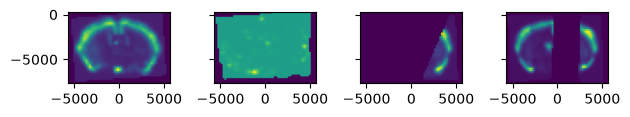

In [2]:
rows = df_genes.index[df_genes['gene'] == 'Rora']
rora_volumes = gene_expression_volumes[rows]
print(df_genes.loc[rows])
print(rora_volumes.shape)

fig, axs = plt.subplots(1, len(rows), sharex=True, sharey=True)
for ax, volume in zip(axs, rora_volumes):
    atlas_agea.plot_cslice(0, ax=ax, volume=volume, cmap='viridis')
fig.tight_layout()

To demonstrate how to using the atlas object, we will display registered coronal and a sagittal slices from the first gene.

The top row is the diffusion MRI Allen template, the middle row corresponds to the brain regions annotations and the bottom row corresponds to the first gene expression volume.

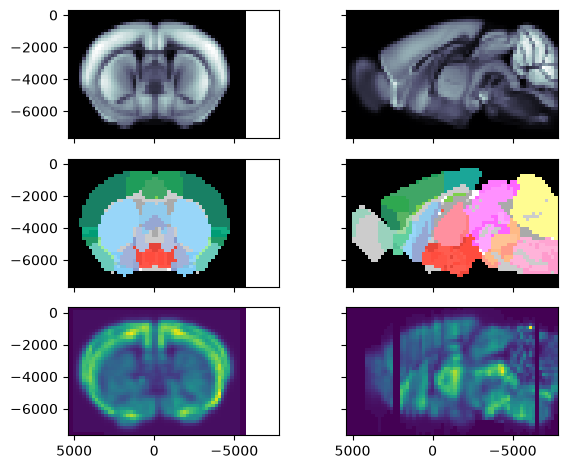

In [3]:
igenes = (0,)
fig, axs = plt.subplots(3, 2, sharex=True, sharey=True)
atlas_agea.plot_cslice(0, ax=axs[0, 0])
atlas_agea.plot_cslice(0, ax=axs[1, 0], volume='annotation')
atlas_agea.plot_cslice(0, ax=axs[2, 0], volume=gene_expression_volumes[igenes[0]], cmap='viridis')
atlas_agea.plot_sslice(0, ax=axs[0, 1])
atlas_agea.plot_sslice(0, ax=axs[1, 1], volume='annotation')
atlas_agea.plot_sslice(0, ax=axs[2, 1], volume=gene_expression_volumes[igenes[0]], cmap='viridis')
fig.tight_layout()

Now we can load a version of the gene expression that has been infilled and post-processed.

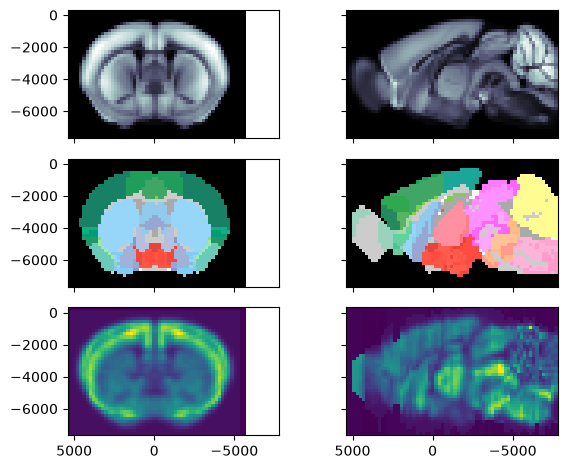

In [4]:
df_genes, gene_expression_volumes, atlas_agea = agea.load(label='processed')
igenes = (0,)
fig, axs = plt.subplots(3, 2, sharex=True, sharey=True)
atlas_agea.plot_cslice(0, ax=axs[0, 0])
atlas_agea.plot_cslice(0, ax=axs[1, 0], volume='annotation')
atlas_agea.plot_cslice(0, ax=axs[2, 0], volume=gene_expression_volumes[igenes[0]], cmap='viridis')
atlas_agea.plot_sslice(0, ax=axs[0, 1])
atlas_agea.plot_sslice(0, ax=axs[1, 1], volume='annotation')
atlas_agea.plot_sslice(0, ax=axs[2, 1], volume=gene_expression_volumes[igenes[0]], cmap='viridis')
fig.tight_layout()

## In my region

The example region is VISp, primary visual cortex; replace `'VISp'` with the Beryl acronym of your own region. The mask selects the voxels of the processed volumes, on their 200 µm grid, that belong to the region, and the table gives the mean of each experiment over them, highest first.

In [5]:
regions = atlas_agea.regions
in_region = regions.acronym[regions.mappings['Beryl'][atlas_agea.label]] == 'VISp'
print(f'{in_region.sum()} voxels')

mean_in_region = gene_expression_volumes[:, in_region].astype(float).mean(axis=1)
df_genes.assign(mean_in_region=mean_in_region).sort_values('mean_in_region', ascending=False).head(10)

885 voxels


,id,gene,mean_in_region
4200,1014,Syt1,39.326015
3373,74958606,8030498B09Rik,38.886149
1053,73769319,Clstn1,35.578381
1692,73931635,Acsl5,35.086944
2275,79591705,App,32.593640
2630,69153759,Nrgn,32.305941
3641,67752306,Serinc1,31.199166
745,74881516,Actb,30.886103
3995,1854,Snap25,30.855676
1948,70616006,Prkar1b,30.829597


The top of this list is genes expressed throughout the brain. To find the genes that differ between regions, compare the region with other regions, as in [From your results to what's known](../tutorials/from-your-results-to-whats-known.ipynb). A gene with more than one experiment appears once per experiment.